In [10]:
import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
DATA_DIR = Path.cwd().parent / "data"
DATA_FILE = DATA_DIR / "sales.csv.gz"
SUBMISSION_DIR = Path.cwd().parent / "submission"
SUBMISSION_FILE_1 = SUBMISSION_DIR / "cohort_retention.csv"
SUBMISSION_FILE_PNG = SUBMISSION_DIR / "cohort_retention_heatmap.png"

In [4]:
datos = pd.read_csv(DATA_FILE, compression='gzip')
datos

,OrderID,ProductID,Category,ProductName,Quantity,Price,TotalAmount,OrderDate,CustomerID,PaymentMethod,SalesChannel,IsReturned
0,1,272,Electronics,Product_272,3,54.21,162.63,2022-04-21 01:48:37,26,Credit Card,In-Store,1
1,2,147,Electronics,Product_147,3,163.68,491.04,2022-02-26 03:09:32,38,Cash,Website,1
2,3,217,Fashion,Product_217,5,205.01,1025.05,2022-07-24 07:00:57,271,Cash,Website,0
3,4,292,Electronics,Product_292,4,163.13,652.52,2022-01-09 09:49:05,414,Cash,Website,1
4,5,423,Fashion,Product_423,3,608.73,1826.19,2022-05-19 09:38:52,368,Cash,Mobile App,1
...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,325,Fashion,Product_325,4,392.23,1568.92,2022-07-20 03:25:54,392,Credit Card,Website,1
996,997,194,Home & Garden,Product_194,2,464.94,929.88,2022-01-21 08:58:14,348,Credit Card,Website,1
997,998,338,Electronics,Product_338,3,496.48,1489.44,2022-07-08 22:06:09,497,PayPal,In-Store,0
998,999,265,Home & Garden,Product_265,2,775.78,1551.56,2022-05-18 21:23:25,84,Cash,Website,1


In [5]:
datos["cohort_month"] = datos.groupby("CustomerID")["OrderDate"].transform("min").str.extract(r"(^.{7})")  # Usar expresiones regulares para extraer el mes en el formato requerido. Se agrupa por CustomerID pero se aplica el min sobre OrderDate
datos["cohort_month_mm"] = datos["cohort_month"].str.extract(r"(.{2}$)").astype(int)                       # Usar expresiones regulares para extraer el mes en el formato requerido. Se extrae los últimos 2 caracteres de la fecha y se convierte a entero
datos["order_month"] = datos["OrderDate"].str.extract(r"^.{5}(.{2})").astype(int)                          # Usar expresiones regulares para extraer el mes en el formato requerido. Se extraen los caracteres 6 y 7
datos["period_index"] = datos["order_month"] - datos["cohort_month_mm"] 

datos["active_customers"] = datos.groupby(["cohort_month", "period_index"])["CustomerID"].transform("nunique")  # Se agrupa por cohort_month y period_index y se aplica nunique sobre CustomerID para obtener el número de clientes activos
datos["cohort_size"] = datos.groupby(["cohort_month"])["CustomerID"].transform("nunique")                       # Se agrupa por cohort_month y se aplica nunique sobre CustomerID para obtener el tamaño de la cohorte
datos["retention_rate"] = datos["active_customers"] / datos["cohort_size"]


COLUMNAS_COHORT_RETENTION = ["cohort_month", "period_index", "active_customers", "cohort_size", "retention_rate"]

datos_cohort_retention = datos[COLUMNAS_COHORT_RETENTION].drop_duplicates().sort_values(by=["cohort_month", "period_index"]).reset_index(drop=True)

In [6]:
with open(SUBMISSION_FILE_1, "w") as f:
    datos_cohort_retention.to_csv(f, index=False)

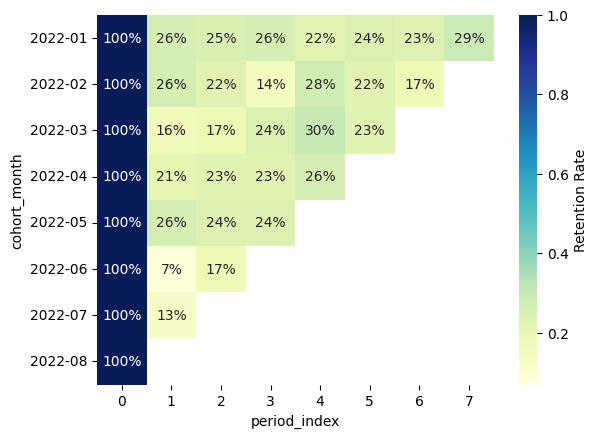

In [9]:
datos_grafico = datos_cohort_retention.pivot(index="cohort_month", columns="period_index", values="retention_rate")
cohort_retention_heatmap = sns.heatmap(datos_grafico, annot=True, fmt=".0%", cmap="YlGnBu", cbar_kws={"label": "Retention Rate"})

In [ ]:
plt.savefig(SUBMISSION_FILE_PNG, bbox_inches="tight", dpi=300)